# Day 4 · 실습 1. YOLO 객체 탐지와 조건 비교

**연계 이론:** 이론 2 · **1.3** Confidence Threshold / **2.2** IoU / **3.3~3.4** NMS / **5.2~5.6** YOLO

사전학습된 YOLO의 탐지 결과를 관찰하고, **Confidence 기준**과 **NMS IoU 기준**을 직접 변경해 비교합니다. 코드는 위에서 아래로 실행하며, `[직접 변경]` 표시가 있는 값만 수정하면 됩니다.

In [2]:
# 0. 준비 — 기존 assets/ 이미지를 사용합니다 (자동 이미지 다운로드 없음).
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import torch

try:
    from ultralytics import YOLO
except ImportError as exc:
    raise ImportError("ultralytics가 없습니다. Notebook 환경에서 `%pip install ultralytics`를 실행하세요.") from exc

# Notebook을 프로젝트 루트 또는 그 하위 폴더에서 실행할 수 있습니다.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "assets" / "coffee.jpg").is_file()
             and (p / "assets" / "chelsea.jpg").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("assets/coffee.jpg와 assets/chelsea.jpg를 찾을 수 없습니다. Notebook과 assets/ 폴더의 위치를 확인하세요.")

ASSET_DIR = ROOT / "assets"
YOLO_OUT = ROOT / "outputs" / "yolo"
WEIGHT_DIR = ROOT / "weights"
YOLO_OUT.mkdir(parents=True, exist_ok=True)
WEIGHT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "yolo26n.pt"
MODEL_FILE = WEIGHT_DIR / MODEL_NAME
MODEL_SOURCE = str(MODEL_FILE) if MODEL_FILE.is_file() else MODEL_NAME
DEVICE = 0 if torch.cuda.is_available() else "cpu"
model = YOLO(MODEL_SOURCE)  # 가중치가 없으면 첫 실행 시 다운로드할 수 있습니다.
print("준비 완료 | 이미지: coffee.jpg, chelsea.jpg | 모델:", MODEL_NAME)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/jian/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
준비 완료 | 이미지: coffee.jpg, chelsea.jpg | 모델: yolo26n.pt


## 1. YOLO 추론과 Confidence 비교 — 이론 2 · 1.3, 5.2~5.6

아래 `CONF_THRESHOLDS` 값만 바꾸어 **같은 이미지에서 탐지 결과가 어떻게 달라지는지** 관찰합니다.

In [3]:
# [직접 변경 ①] Confidence 기준을 바꾼 뒤 이 셀부터 다시 실행하세요.
IMAGE_FILES = ["coffee.jpg", "chelsea.jpg"]
CONF_THRESHOLDS = [0.15, 0.30, 0.60]

assert CONF_THRESHOLDS and len(set(CONF_THRESHOLDS)) == len(CONF_THRESHOLDS)
assert all(0 < conf <= 1 for conf in CONF_THRESHOLDS)

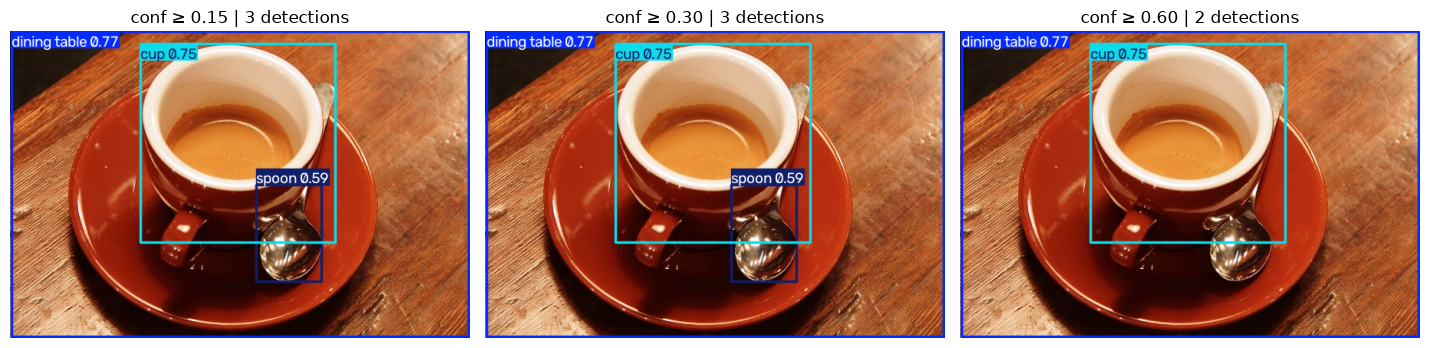

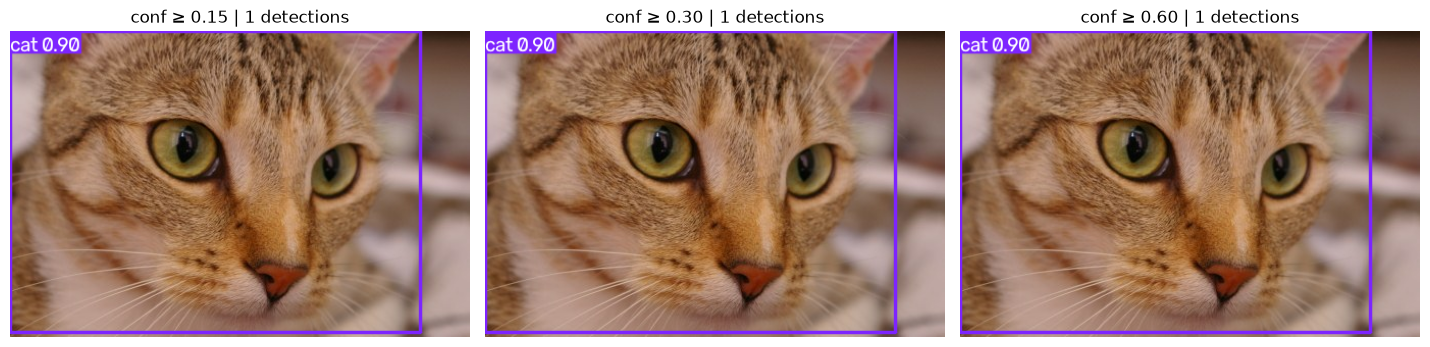

탐지 개수 비교
  coffee.jpg   conf=0.15 → 3개
  coffee.jpg   conf=0.30 → 3개
  coffee.jpg   conf=0.60 → 2개
  chelsea.jpg  conf=0.15 → 1개
  chelsea.jpg  conf=0.30 → 1개
  chelsea.jpg  conf=0.60 → 1개
저장: /Users/jian/Documents/module2_cv_nlp/outputs/yolo/yolo_detections.json


In [4]:
# 사전학습 모델 추론 → Bounding Box 시각화 → 다음 실습용 JSON 저장
results_for_next = {
    "model": MODEL_NAME,
    "confidence_thresholds": CONF_THRESHOLDS,
    "images": {},
    "note": "YOLO predictions only; ground-truth evaluation is done in the next notebook.",
}
count_rows = []

for image_name in IMAGE_FILES:
    image_path = ASSET_DIR / image_name
    if not image_path.is_file():
        raise FileNotFoundError(f"샘플 이미지가 없습니다: {image_path}")
    width, height = Image.open(image_path).size
    image_record = {"width": width, "height": height, "thresholds": {}}

    fig, axes = plt.subplots(1, len(CONF_THRESHOLDS),
                             figsize=(4.8 * len(CONF_THRESHOLDS), 4.2))
    axes = np.atleast_1d(axes)

    for ax, threshold in zip(axes, CONF_THRESHOLDS):
        result = model.predict(source=str(image_path), conf=threshold,
                               imgsz=640, device=DEVICE, save=False, verbose=False)[0]
        detections = []
        if result.boxes is not None:
            boxes = result.boxes.xyxy.cpu().numpy()
            scores = result.boxes.conf.cpu().numpy()
            class_ids = result.boxes.cls.cpu().numpy().astype(int)
            for box, score, class_id in zip(boxes, scores, class_ids):
                detections.append({
                    "class_id": int(class_id),
                    "class_name": str(result.names[int(class_id)]),
                    "confidence": float(score),
                    "xyxy": [float(v) for v in box],
                })

        key = f"{threshold:.2f}"
        image_record["thresholds"][key] = detections
        count_rows.append({"image": image_name, "conf_threshold": key,
                           "num_detections": len(detections)})
        annotated_rgb = np.ascontiguousarray(result.plot()[:, :, ::-1])
        Image.fromarray(annotated_rgb).save(YOLO_OUT / f"{image_path.stem}_conf_{key}.png")
        ax.imshow(annotated_rgb)
        ax.set_title(f"conf ≥ {key} | {len(detections)} detections")
        ax.axis("off")

    results_for_next["images"][image_name] = image_record
    fig.tight_layout()
    fig.savefig(YOLO_OUT / f"{image_path.stem}_threshold_comparison.png",
                dpi=130, bbox_inches="tight")
    plt.show()

with (YOLO_OUT / "yolo_detections.json").open("w", encoding="utf-8") as f:
    json.dump(results_for_next, f, ensure_ascii=False, indent=2)
with (YOLO_OUT / "threshold_counts.csv").open("w", encoding="utf-8-sig", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["image", "conf_threshold", "num_detections"])
    writer.writeheader()
    writer.writerows(count_rows)

print("탐지 개수 비교")
for row in count_rows:
    print(f'  {row["image"]:12} conf={row["conf_threshold"]} → {row["num_detections"]}개')
print("저장:", YOLO_OUT / "yolo_detections.json")

## 2. IoU와 NMS 확인 — 이론 2 · 2.2, 3.3~3.4

**A·B·C는 실제 YOLO 출력이 아니라 교안에 나온 설명용 Box**입니다. `NMS_IOU_THRESHOLDS`를 바꿔 어떤 후보가 남는지 확인합니다.

In [5]:
# [직접 변경 ②] NMS IoU 기준만 변경해서 비교하세요.
NMS_IOU_THRESHOLDS = [0.50, 0.75]
assert all(0 <= t <= 1 for t in NMS_IOU_THRESHOLDS)

IoU(A, B) = 0.667
All candidates → ['A', 'B', 'C']
NMS IoU = 0.50 → ['A', 'C']
NMS IoU = 0.75 → ['A', 'B', 'C']


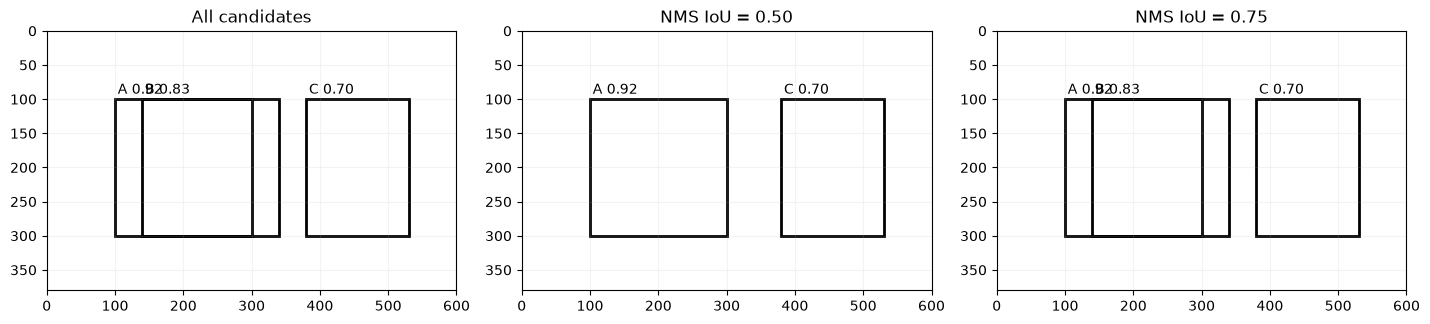

In [6]:
# 이론 2 · 2.2: IoU / 3.3: NMS의 처리 순서
BOXES = [[100, 100, 300, 300], [140, 100, 340, 300], [380, 100, 530, 300]]
SCORES = [0.92, 0.83, 0.70]
LABELS = ["A", "B", "C"]

def box_iou(a, b):
    left, top = max(a[0], b[0]), max(a[1], b[1])
    right, bottom = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, right-left) * max(0, bottom-top)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - intersection
    return intersection / union if union else 0.0

def nms(boxes, scores, threshold):
    remaining = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)
    kept = []
    while remaining:
        best = remaining.pop(0)
        kept.append(best)
        remaining = [i for i in remaining if box_iou(boxes[best], boxes[i]) <= threshold]
    return kept

print(f"IoU(A, B) = {box_iou(BOXES[0], BOXES[1]):.3f}")
assert abs(box_iou(BOXES[0], BOXES[1]) - 2/3) < 1e-6

cases = [("All candidates", list(range(3)))]
cases += [(f"NMS IoU = {t:.2f}", nms(BOXES, SCORES, t))
          for t in NMS_IOU_THRESHOLDS]
fig, axes = plt.subplots(1, len(cases), figsize=(4.8 * len(cases), 3.8))
for ax, (label, kept) in zip(np.atleast_1d(axes), cases):
    ax.set_xlim(0, 600)
    ax.set_ylim(380, 0)
    ax.set_aspect("equal")
    ax.set_title(label)
    for i in kept:
        x1, y1, x2, y2 = BOXES[i]
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1,
                               fill=False, linewidth=2))
        ax.text(x1+4, y1-8, f"{LABELS[i]} {SCORES[i]:.2f}", fontsize=10)
    ax.grid(alpha=0.15)
    print(label, "→", [LABELS[i] for i in kept])
fig.tight_layout()
fig.savefig(YOLO_OUT / "nms_illustration.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. 이번 실습 간단 요약

- **Confidence Threshold:** 신뢰도 점수로 탐지 후보를 선택합니다. 값이 달라지면 표시되는 객체가 달라질 수 있습니다.
- **IoU와 NMS:** 겹치는 후보를 비교하고 중복 탐지를 정리합니다. 설명용 예제에서 IoU(A,B)는 약 0.667입니다.
- **평가와의 차이:** 탐지 개수가 늘었다고 정확도가 높아진 것은 아닙니다. **실습 2(이론 4 연계)**에서는 저장된 `outputs/yolo/yolo_detections.json`을 기존 `assets/ground_truth_demo.json`과 비교하여 TP·FP·FN을 판정합니다.